# 03 – Model Design: Advanced ML (Gaussian Mixture Model)

**Project:** Analisis Pola Persebaran Catatan Keanekaragaman Hayati di Indonesia Menggunakan Metode Clustering

Notebook ini melatih model **Gaussian Mixture Model (GMM)** sebagai model advanced. Unit analisisnya adalah **grid-tahun**, yaitu satu wilayah grid pada satu tahun pengamatan, bukan spesies secara individual.

### Cara menggunakan notebook
1. Jalankan Notebook 02 sampai selesai dan pastikan folder `hasil_data_preparation_clustering` berhasil dibuat.
2. Bila Notebook 02 dan notebook ini menggunakan runtime Colab yang sama, file akan dibaca langsung.
3. Bila menggunakan runtime baru, siapkan ZIP folder `hasil_data_preparation_clustering`. Notebook ini akan meminta ZIP tersebut untuk diunggah.
4. Jalankan seluruh cell secara berurutan.

**Catatan:** GMM menggunakan data training untuk belajar dan data validation untuk evaluasi. Data test belum digunakan pada tahap ini.

## 1. Import Library dan Menyiapkan Folder

Cell ini memanggil library yang digunakan untuk membaca data, melatih GMM, menghitung evaluasi, dan menyimpan hasil. Folder hasil Data Preparation ditetapkan sesuai dengan lokasi penyimpanan pada Notebook 02.

In [4]:
import pandas as pd
import numpy as np
import json
import zipfile
import joblib
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

PREP_DIR = Path("/content/hasil_data_preparation_clustering")
OUTPUT_DIR = Path("/content/hasil_advanced_gmm")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Library berhasil disiapkan.")
print("Folder Data Preparation:", PREP_DIR)

Library berhasil disiapkan.
Folder Data Preparation: /content/hasil_data_preparation_clustering


## 2. Memastikan File Data Preparation Tersedia

Notebook 02 menyimpan hasil preprocessing di folder `hasil_data_preparation_clustering`. Jika folder tersebut belum ada pada runtime ini, unggah ZIP hasil Data Preparation agar file dapat dibaca.

In [5]:
if not PREP_DIR.exists():
    from google.colab import files

    print("Folder hasil Data Preparation belum ditemukan.")
    print("Silakan unggah ZIP folder hasil_data_preparation_clustering.")
    uploaded = files.upload()

    nama_zip = list(uploaded.keys())[0]

    with zipfile.ZipFile(nama_zip, "r") as zip_ref:
        zip_ref.extractall("/content")

if not PREP_DIR.exists():
    raise FileNotFoundError(
        "Folder hasil_data_preparation_clustering belum ditemukan. "
        "Pastikan ZIP yang diunggah berisi folder tersebut."
    )

print("Folder Data Preparation berhasil ditemukan.")

Folder hasil Data Preparation belum ditemukan.
Silakan unggah ZIP folder hasil_data_preparation_clustering.


Saving hasil_data_preparation_clustering.zip to hasil_data_preparation_clustering.zip
Folder Data Preparation berhasil ditemukan.


## 3. Memeriksa File yang Dibutuhkan

Nama file pada bagian ini disesuaikan dengan hasil penyimpanan Notebook 02. Pemeriksaan dilakukan sebelum data dibaca agar kesalahan file dapat diketahui lebih awal.

In [6]:
file_wajib = [
    "X_train_scaled.npy",
    "X_validation_scaled.npy",
    "X_test_scaled.npy",
    "train_grid_year.csv",
    "validation_grid_year.csv",
    "test_grid_year.csv",
    "feature_columns.json"
]

for nama_file in file_wajib:
    lokasi_file = PREP_DIR / nama_file
    if not lokasi_file.exists():
        raise FileNotFoundError("File belum ditemukan: " + nama_file)

print("Semua file yang dibutuhkan sudah tersedia.")

Semua file yang dibutuhkan sudah tersedia.


## 4. Membaca Data Training, Validation, dan Test

Data fitur yang sudah distandarisasi dibaca dari file NPY, sedangkan informasi wilayah dan tahun dibaca dari file CSV. Daftar nama fitur dibaca dari `feature_columns.json` agar urutan fitur tetap sesuai dengan Notebook 02.

In [7]:
X_train = np.load(PREP_DIR / "X_train_scaled.npy")
X_val = np.load(PREP_DIR / "X_validation_scaled.npy")
X_test = np.load(PREP_DIR / "X_test_scaled.npy")

train_data = pd.read_csv(PREP_DIR / "train_grid_year.csv")
val_data = pd.read_csv(PREP_DIR / "validation_grid_year.csv")
test_data = pd.read_csv(PREP_DIR / "test_grid_year.csv")

with open(PREP_DIR / "feature_columns.json", "r", encoding="utf-8") as file:
    feature_cols = json.load(file)

print("Jumlah data training:", X_train.shape)
print("Jumlah data validation:", X_val.shape)
print("Jumlah data test:", X_test.shape)
print("Jumlah fitur:", len(feature_cols))
print("Nama fitur:", feature_cols)

Jumlah data training: (4744, 9)
Jumlah data validation: (1505, 9)
Jumlah data test: (1216, 9)
Jumlah fitur: 9
Nama fitur: ['log_total_records', 'log_species_richness', 'log_family_richness', 'log_class_richness', 'prop_animalia', 'prop_plantae', 'prop_fungi', 'prop_other', 'prop_unknown']


## 5. Penjelasan Fitur yang Digunakan

GMM menggunakan sembilan fitur yang sudah dibentuk pada Notebook 02. Empat fitur pertama merupakan jumlah yang telah ditransformasi dengan `log1p`, sedangkan lima fitur berikutnya merupakan proporsi catatan berdasarkan kelompok kingdom.

In [8]:
penjelasan_fitur = pd.DataFrame({
    "Nama Fitur": [
        "log_total_records",
        "log_species_richness",
        "log_family_richness",
        "log_class_richness",
        "prop_animalia",
        "prop_plantae",
        "prop_fungi",
        "prop_other",
        "prop_unknown"
    ],
    "Penjelasan": [
        "Menunjukkan jumlah catatan kemunculan yang tercatat pada satu grid dan tahun. Nilainya sudah ditransformasi log1p agar skala jumlah lebih terkendali.",
        "Menunjukkan jumlah spesies unik yang tercatat pada satu grid dan tahun. Fitur ini menggambarkan kekayaan spesies yang terdokumentasi, bukan jumlah populasi sebenarnya.",
        "Menunjukkan jumlah famili taksonomi unik pada satu grid dan tahun. Nilainya telah ditransformasi log1p agar perbedaan jumlah tidak terlalu mencolok.",
        "Menunjukkan jumlah kelas taksonomi unik pada satu grid dan tahun. Fitur ini menggambarkan variasi kelompok organisme pada tingkat kelas yang tercatat.",
        "Menunjukkan proporsi catatan yang termasuk kelompok Animalia. Nilai yang lebih besar berarti catatan hewan mengambil bagian lebih besar pada grid-tahun tersebut.",
        "Menunjukkan proporsi catatan yang termasuk kelompok Plantae. Nilai yang lebih besar berarti catatan tumbuhan mengambil bagian lebih besar pada grid-tahun tersebut.",
        "Menunjukkan proporsi catatan yang termasuk kelompok Fungi. Fitur ini menggambarkan bagian catatan jamur dalam keseluruhan catatan pada grid-tahun tersebut.",
        "Menunjukkan proporsi catatan dari kelompok kingdom selain Animalia, Plantae, Fungi, dan Unknown. Fitur ini menggabungkan kelompok lain ke dalam satu kategori.",
        "Menunjukkan proporsi catatan yang informasi kingdom-nya tidak diketahui. Nilai ini menggambarkan bagian catatan yang belum memiliki informasi kingdom."
    ]
})

display(penjelasan_fitur)

,Nama Fitur,Penjelasan
0,log_total_records,Menunjukkan jumlah catatan kemunculan yang ter...
1,log_species_richness,Menunjukkan jumlah spesies unik yang tercatat ...
2,log_family_richness,Menunjukkan jumlah famili taksonomi unik pada ...
3,log_class_richness,Menunjukkan jumlah kelas taksonomi unik pada s...
4,prop_animalia,Menunjukkan proporsi catatan yang termasuk kel...
5,prop_plantae,Menunjukkan proporsi catatan yang termasuk kel...
6,prop_fungi,Menunjukkan proporsi catatan yang termasuk kel...
7,prop_other,Menunjukkan proporsi catatan dari kelompok kin...
8,prop_unknown,Menunjukkan proporsi catatan yang informasi ki...


## 6. Model Advanced: Gaussian Mixture Model (GMM)

Gaussian Mixture Model adalah metode clustering yang menganggap data terbentuk dari gabungan beberapa distribusi Gaussian. Setiap data akan memiliki peluang untuk masuk ke setiap cluster, kemudian ditempatkan pada cluster dengan peluang terbesar.

**Alasan pemilihan:** GMM dipilih karena dapat membentuk cluster dengan pola sebaran yang lebih fleksibel dibandingkan K-Means. Model ini juga memberikan probabilitas keanggotaan setiap data pada cluster.

**Keunggulan:** dapat menangani cluster dengan bentuk dan sebaran yang berbeda serta menghasilkan probabilitas keanggotaan.

**Kelemahan:** jumlah cluster perlu ditentukan di awal dan hasilnya dapat dipengaruhi oleh inisialisasi serta asumsi distribusi Gaussian.

**Hypothesis space:** kemungkinan model campuran Gaussian yang dibentuk dari jumlah komponen, bobot, rata-rata, dan kovarians setiap komponen.

**Inductive bias:** model mengasumsikan data dapat dijelaskan sebagai gabungan beberapa distribusi Gaussian.

## 7. Menentukan Parameter dan Melatih GMM

GMM dilatih menggunakan data training yang sudah distandarisasi. Jumlah cluster awal ditetapkan empat sebagai konfigurasi percobaan, bukan sebagai jumlah cluster terbaik yang sudah terbukti.

In [9]:
gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",
    random_state=42,
    max_iter=200
)

gmm.fit(X_train)

print("Model GMM selesai dilatih.")
print("Berhasil konvergen:", gmm.converged_)
print("Jumlah iterasi:", gmm.n_iter_)

Model GMM selesai dilatih.
Berhasil konvergen: True
Jumlah iterasi: 16


## 8. Memprediksi Cluster pada Validation Set

Model yang sudah dilatih digunakan untuk menentukan cluster pada data validation. Hasil prediksi digabungkan dengan informasi grid dan tahun agar hasil clustering mudah dianalisis.

In [10]:
cluster_val = gmm.predict(X_val)
probabilitas = gmm.predict_proba(X_val)

hasil_validation = val_data.copy()
hasil_validation["cluster_gmm"] = cluster_val
hasil_validation["probabilitas_tertinggi"] = probabilitas.max(axis=1)

print("Contoh hasil clustering pada validation set:")
display(hasil_validation.head())

print("Jumlah grid-tahun pada setiap cluster:")
display(hasil_validation["cluster_gmm"].value_counts().sort_index())

Contoh hasil clustering pada validation set:


,grid_id,grid_lat_center,grid_lon_center,year,total_records,species_richness,family_richness,class_richness,log_total_records,log_species_richness,log_family_richness,log_class_richness,prop_animalia,prop_plantae,prop_fungi,prop_other,prop_unknown,cluster_gmm,probabilitas_tertinggi
0,-10_252,-4.75,126.25,2015,1,1,1,1,0.693147,0.693147,0.693147,0.693147,1.00,0.00,0.0,0.0,0.0,1,1.000000
1,-10_253,-4.75,126.75,2016,1,1,1,1,0.693147,0.693147,0.693147,0.693147,1.00,0.00,0.0,0.0,0.0,1,1.000000
2,-10_260,-4.75,130.25,2015,40,30,17,5,3.713572,3.433987,2.890372,1.791759,0.95,0.05,0.0,0.0,0.0,1,0.999986
3,-10_260,-4.75,130.25,2016,149,128,32,4,5.010635,4.859812,3.496508,1.609438,1.00,0.00,0.0,0.0,0.0,1,1.000000
4,-10_260,-4.75,130.25,2017,16,16,14,1,2.833213,2.833213,2.708050,0.693147,1.00,0.00,0.0,0.0,0.0,1,1.000000


Jumlah grid-tahun pada setiap cluster:


,count
cluster_gmm,
0,75
1,1131
2,2
3,297


## 9. Evaluasi Model pada Validation Set

Evaluasi dilakukan menggunakan Silhouette Score, Davies-Bouldin Index, dan Calinski-Harabasz Score. Karena dataset tidak memiliki label target, ketiga metrik tersebut digunakan untuk melihat kualitas pemisahan cluster secara internal.

In [11]:
jumlah_cluster = len(np.unique(cluster_val))

if jumlah_cluster >= 2 and jumlah_cluster < len(X_val):
    skor_silhouette = silhouette_score(
        X_val,
        cluster_val,
        sample_size=min(5000, len(X_val)),
        random_state=42
    )
    skor_davies = davies_bouldin_score(X_val, cluster_val)
    skor_calinski = calinski_harabasz_score(X_val, cluster_val)

    hasil_evaluasi = pd.DataFrame({
        "Metrik": [
            "Silhouette Score",
            "Davies-Bouldin Index",
            "Calinski-Harabasz Score"
        ],
        "Nilai": [
            skor_silhouette,
            skor_davies,
            skor_calinski
        ]
    })
    display(hasil_evaluasi)
else:
    print("Evaluasi metrik tidak dapat dilakukan karena jumlah cluster tidak memenuhi syarat.")

,Metrik,Nilai
0,Silhouette Score,0.194542
1,Davies-Bouldin Index,1.156781
2,Calinski-Harabasz Score,546.619884


Perbandingan K-Means Baseline dengan GMM Advanced.

In [12]:
import pandas as pd

# Memasukkan skor K-Means dari Notebook Baseline
silhouette_kmeans = 0.5078
davies_kmeans = 0.529
calinski_kmeans = 1762.821

# Membandingkan hasil K-Means dan GMM
perbandingan = pd.DataFrame({
    "Model": ["K-Means Baseline", "GMM Advanced"],
    "Silhouette Score": [silhouette_kmeans, skor_silhouette],
    "Davies-Bouldin Index": [davies_kmeans, skor_davies],
    "Calinski-Harabasz Score": [calinski_kmeans, skor_calinski]
})

display(perbandingan.round(4))

,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means Baseline,0.5078,0.5290,1762.8210
1,GMM Advanced,0.1945,1.1568,546.6199


## 10. Visualisasi Jumlah Data pada Setiap Cluster

Grafik memperlihatkan banyaknya grid-tahun yang masuk ke setiap cluster pada validation set. Grafik ini membantu melihat apakah jumlah anggota setiap cluster tersebar merata atau didominasi kelompok tertentu.

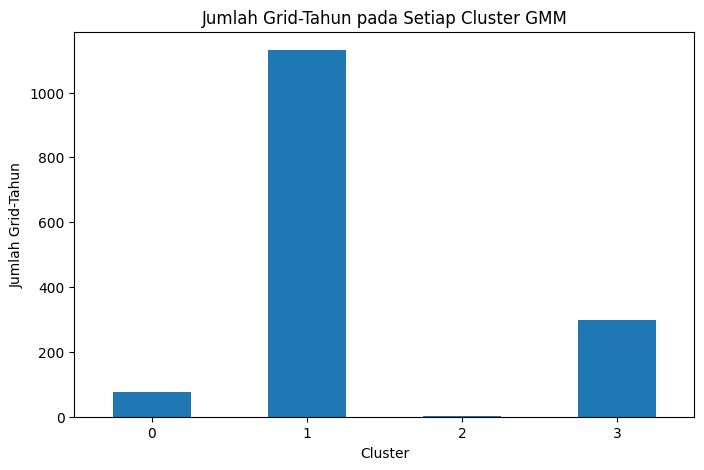

In [13]:
jumlah_data_cluster = hasil_validation["cluster_gmm"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
jumlah_data_cluster.plot(kind="bar")
plt.title("Jumlah Grid-Tahun pada Setiap Cluster GMM")
plt.xlabel("Cluster")
plt.ylabel("Jumlah Grid-Tahun")
plt.xticks(rotation=0)
plt.show()

## 11. Melihat Karakteristik Setiap Cluster

Rata-rata beberapa fitur ditampilkan untuk membantu memahami karakteristik setiap cluster. Nilai jumlah catatan dan kekayaan taksonomi menunjukkan pola dokumentasi, bukan ukuran pasti populasi organisme di wilayah tersebut.

In [14]:
kolom_karakteristik = [
    "total_records",
    "species_richness",
    "family_richness",
    "class_richness",
    "prop_animalia",
    "prop_plantae",
    "prop_fungi",
    "prop_other",
    "prop_unknown"
]

kolom_karakteristik = [
    kolom for kolom in kolom_karakteristik
    if kolom in hasil_validation.columns
]

profil_cluster = hasil_validation.groupby("cluster_gmm")[kolom_karakteristik].mean().round(2)

display(profil_cluster)

,total_records,species_richness,family_richness,class_richness,prop_animalia,prop_plantae,prop_fungi,prop_other,prop_unknown
cluster_gmm,,,,,,,,,
0,3317.91,458.67,163.12,16.87,0.88,0.10,0.00,0.02,0.00
1,456.53,72.81,32.75,4.57,0.99,0.01,0.00,0.00,0.00
2,48.50,48.00,22.00,2.50,0.11,0.00,0.00,0.87,0.02
3,93.01,42.06,22.36,4.66,0.47,0.52,0.01,0.00,0.00


## 12. Menyimpan Model dan Hasil

Model GMM, hasil cluster validation, dan tabel evaluasi disimpan ke folder `hasil_advanced_gmm`. File tersebut dapat digunakan kembali pada tahap analisis berikutnya.

In [15]:
joblib.dump(gmm, OUTPUT_DIR / "gmm_advanced.joblib")
hasil_validation.to_csv(OUTPUT_DIR / "gmm_validation_clusters.csv", index=False)
profil_cluster.to_csv(OUTPUT_DIR / "gmm_cluster_profile.csv")

if "hasil_evaluasi" in globals():
    hasil_evaluasi.to_csv(OUTPUT_DIR / "gmm_validation_metrics.csv", index=False)

print("Hasil Advanced ML berhasil disimpan di:", OUTPUT_DIR)

for nama_file in OUTPUT_DIR.iterdir():
    print("-", nama_file.name)

Hasil Advanced ML berhasil disimpan di: /content/hasil_advanced_gmm
- gmm_cluster_profile.csv
- gmm_validation_clusters.csv
- gmm_advanced.joblib
- gmm_validation_metrics.csv


## 13. Kesimpulan Sementara

GMM digunakan untuk mengelompokkan grid-tahun berdasarkan jumlah catatan, kekayaan taksonomi, dan komposisi kelompok kingdom. Hasil evaluasi pada validation set digunakan untuk melihat kualitas pemisahan cluster.

**Catatan interpretasi:** cluster menggambarkan pola catatan keanekaragaman hayati yang terdokumentasi. Hasilnya tidak boleh langsung diartikan sebagai jumlah populasi atau kondisi keanekaragaman hayati sebenarnya karena data juga dipengaruhi oleh intensitas pengamatan dan pendataan.